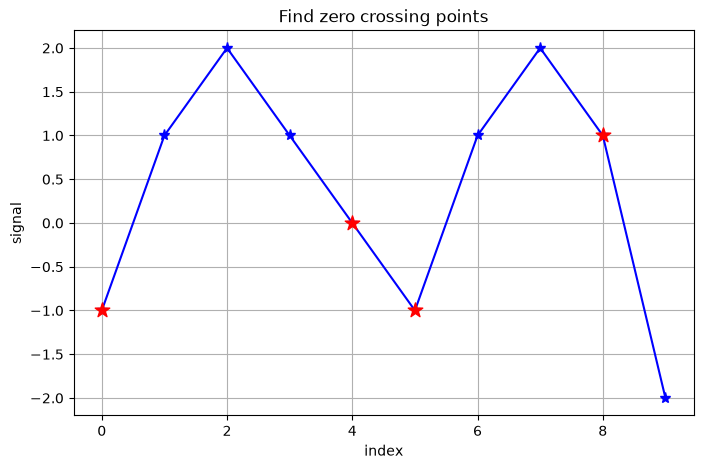

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Signal donné dans l'exemple
signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])
index = np.arange(len(signal))

# Indices des points marqués en rouge sur le graphique
points = [0, 4, 5, 8]

plt.figure(figsize=(8, 5))
plt.plot(index, signal, color="blue", marker="*", markersize=8)
plt.scatter(
    index[points],
    signal[points],
    color="red",
    marker="*",
    s=120,
    zorder=3
)

plt.grid(True)
plt.xlabel("index")
plt.ylabel("signal")
plt.title("Find zero crossing points")
plt.show()

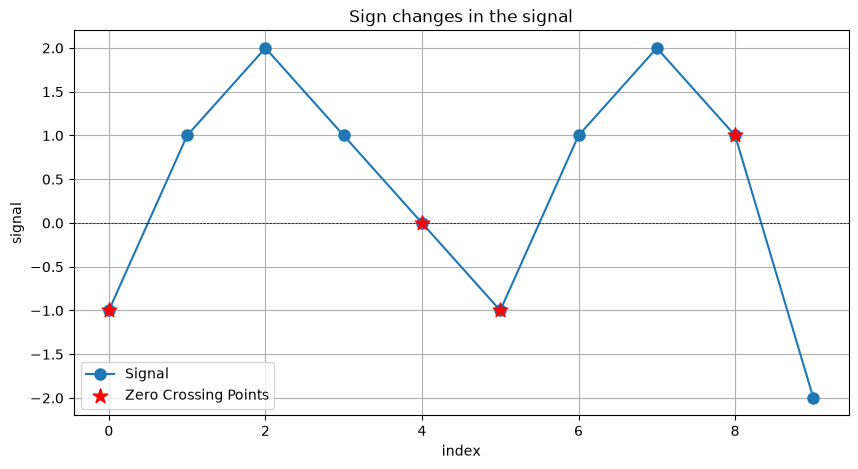

In [2]:
#Case 1 : the signal is exactly zero at some points (like index 4 and 5 in this case). In this case, we can consider these points as zero crossings.
i_exact_zero_crossings = np.where(signal == 0)[0]

#Case 2 : the signal crosses zero
sign_signal = np.sign(signal)
changes = np.diff(sign_signal)

i_zero_crossings = np.where(changes != 0)[0]

# find zero crossings
sign_signal = np.sign(signal)
changes = np.diff(sign_signal)

plt.figure(figsize=(10, 5))
plt.plot(index, signal, marker="o", markersize=8)
plt.scatter(
    index[points],
    signal[points],
    color="red",
    marker="*",
    s=120,
    zorder=3)


plt.xlabel("index")
plt.ylabel("signal")
plt.title("Sign changes in the signal")
plt.xlabel("index")
plt.ylabel("signal")
plt.axhline(0, color='black', lw=0.5, ls='--')
plt.grid()
plt.legend(["Signal", "Zero Crossing Points"])
plt.show()




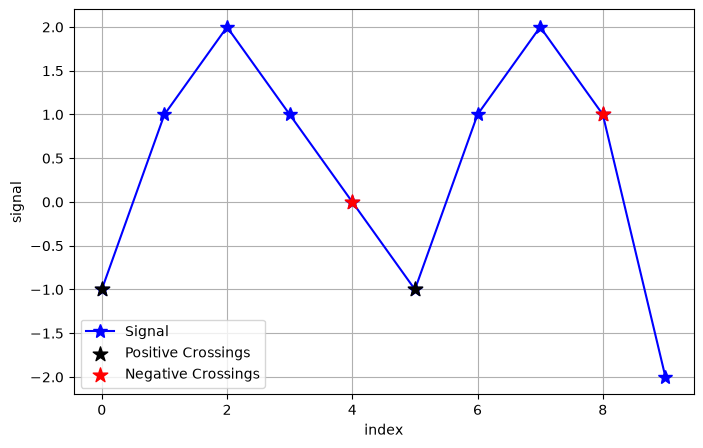

In [3]:
# Même signal que dans l'exemple précédent
signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])
index = np.arange(len(signal))

# points de croisement positifs et négatifs
positive_crossings = [0, 5]
negative_crossings = [4, 8]

plt.figure(figsize=(8, 5))

# Tracer le signal
plt.plot(index, signal, color="blue", marker="*", markersize=10, label="Signal", zorder=2)

# Marquer les croisements positifs en noir
plt.scatter(
    index[positive_crossings],
    signal[positive_crossings],
    color="black",
    marker="*",
    s=120,
    label="Positive Crossings",
    zorder=3
)

# Marquer les croisements négatifs en rouge
plt.scatter(
    index[negative_crossings],
    signal[negative_crossings],
    color="red",
    marker="*",
    s=120,
    label="Negative Crossings",
    zorder=3
)

plt.grid(True)
plt.xlabel("index")
plt.ylabel("signal")
plt.legend()
plt.show()

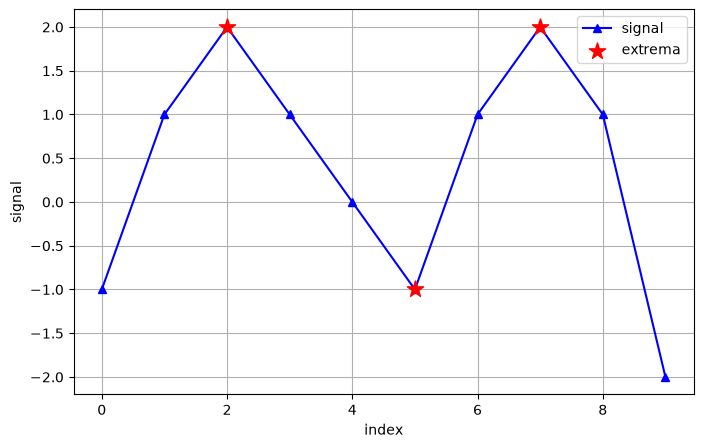

In [4]:
signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])
index = np.arange(len(signal))

# Dérivée approximative
derivative = np.diff(signal)

# Un changement de signe de la dérivée indique un extremum local
extrema_indices = np.where(derivative[:-1] * derivative[1:] < 0)[0] + 1

# Tracer le signal et marquer les extrema
plt.figure(figsize=(8, 5))
plt.plot(index, signal, color="blue", marker="^", label="signal")
plt.scatter(
    index[extrema_indices],
    signal[extrema_indices],
    color="red",
    marker="*",
    s=150,
    label="extrema",
    zorder=3
)

plt.xlabel("index")
plt.ylabel("signal")
plt.grid(True)
plt.legend()
plt.show()

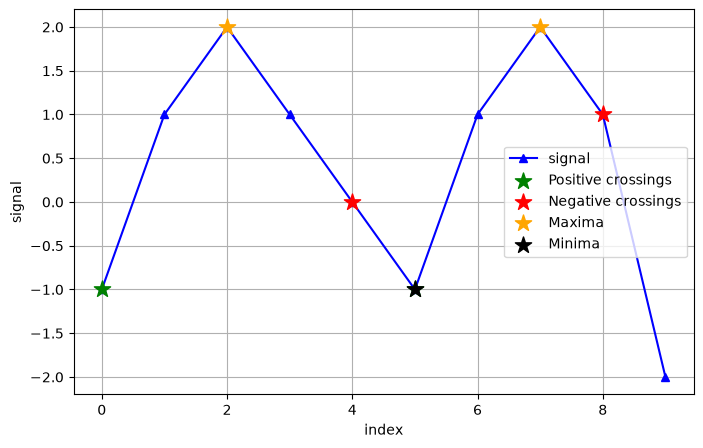

In [5]:
import numpy as np
import matplotlib.pyplot as plt


def find_zero_crossings(signal):
    """Renvoie les positions des passages du signal par zéro."""
    positive = []
    negative = []

    for i in range(len(signal) - 1):
        if signal[i] < 0 and signal[i + 1] >= 0:
            positive.append(i)
        elif signal[i] >= 0 and signal[i + 1] < 0:
            negative.append(i)

    return positive, negative


def find_extrema(signal):
    """Renvoie les indices des maxima et minima locaux."""
    derivative = np.diff(signal)
    maxima = []
    minima = []

    for i in range(1, len(derivative)):
        if derivative[i - 1] > 0 and derivative[i] < 0:
            maxima.append(i)
        elif derivative[i - 1] < 0 and derivative[i] > 0:
            minima.append(i)

    return maxima, minima


def plot_signal(signal):
    """Trace le signal."""
    index = np.arange(len(signal))
    plt.plot(index, signal, color="blue", marker="^", label="signal")


def plot_points(signal, points, label, color):
    """Ajoute des points remarquables au graphique."""
    if points:
        plt.scatter(
            points,
            signal[points],
            color=color,
            marker="*",
            s=150,
            label=label,
            zorder=3,
        )


# Signal des exemples précédents
signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])

# Trouver les points remarquables
positive_crossings, negative_crossings = find_zero_crossings(signal)
maxima, minima = find_extrema(signal)

# Tracer le signal et les points trouvés
plt.figure(figsize=(8, 5))
plot_signal(signal)
plot_points(signal, positive_crossings, "Positive crossings", "green")
plot_points(signal, negative_crossings, "Negative crossings", "red")
plot_points(signal, maxima, "Maxima", "orange")
plot_points(signal, minima, "Minima", "black")

plt.xlabel("index")
plt.ylabel("signal")
plt.grid(True)
plt.legend()
plt.show()

In [6]:
# Passages par zéro positifs (de négatif vers positif)
zero_pos = [i for i in range(len(signal)-1) if signal[i] < 0 and signal[i+1] > 0]
# Passages par zéro négatifs (de positif vers négatif)
zero_neg = [i for i in range(len(signal)-1) if signal[i] > 0 and signal[i+1] < 0]
maxima = [i for i in range(1, len(signal)-1) if signal[i] > signal[i-1] and signal[i] > signal[i+1]]
minima = [i for i in range(1, len(signal)-1) if signal[i] < signal[i-1] and signal[i] < signal[i+1]]

print("Passages par zéro positifs :", zero_pos)
print("Passages par zéro négatifs :", zero_neg)
print("Maxima locaux :", maxima)
print("Minima locaux :", minima)

Passages par zéro positifs : [0, 5]
Passages par zéro négatifs : [8]
Maxima locaux : [2, 7]
Minima locaux : [5]
